In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
print(crosstab)
                       

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [4]:
ct = pd.crosstab(df['category'], df['isBestSeller'])

ct['total'] = ct[False] + ct[True]
ct['bestseller_proportion'] = ct[True] / ct['total']

ct_sorted = ct.sort_values('bestseller_proportion', ascending=False)

print(ct_sorted[['bestseller_proportion']])

isBestSeller                      bestseller_proportion
category                                               
Grocery                                        0.058135
Smart Home Security & Lighting                 0.057692
Health & Personal Care                         0.057686
Mobile Phone Accessories                       0.042471
Power & Hand Tools                             0.035339
...                                                 ...
CD, Disc & Tape Players                        0.000000
General Music-Making Accessories               0.000000
Snowboard Boots                                0.000000
Boxes & Organisers                             0.000000
eBook Readers & Accessories                    0.000000

[296 rows x 1 columns]


In [5]:
# Grocery is more prevalent as a best-seller

In [6]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(ct)

print("Chi2:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi2: 36684.384144034884
p-value: 0.0
Degrees of freedom: 885


In [8]:
import numpy as np

n = ct.sum().sum()
r, k = ct.shape

cramers_v = np.sqrt(chi2 / (n * (min(r-1, k-1))))

print("Cramér's V:", cramers_v)

Cramér's V: 0.050020188016717454


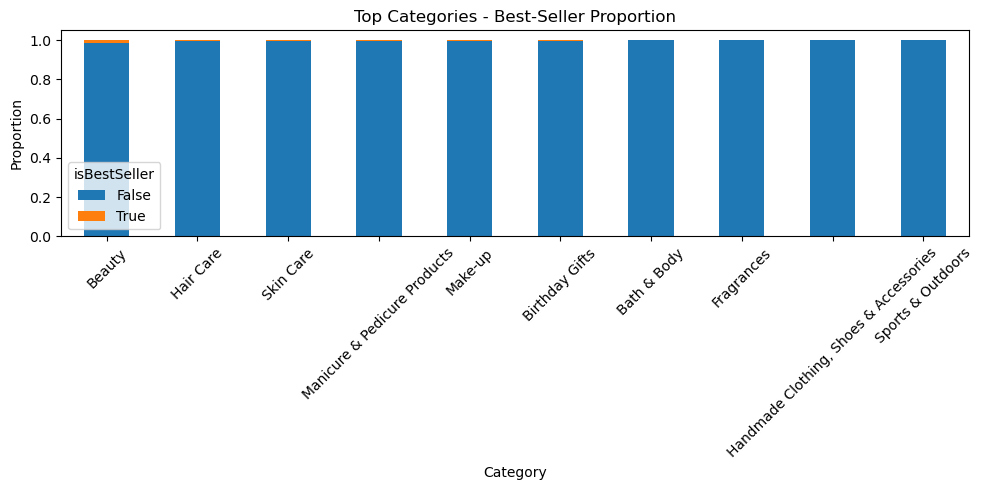

In [10]:
top_categories = df['category'].value_counts().head(10).index

df_top = df[df['category'].isin(top_categories)]

ct = pd.crosstab(df_top['category'], df_top['isBestSeller'], normalize='index')
ct = ct.sort_values(by=True, ascending=False)

ct.plot(kind='bar', stacked=True, figsize=(10,5))

plt.title('Top Categories - Best-Seller Proportion')
plt.xlabel('Category')
plt.ylabel('Proportion')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [14]:
import pandas as pd

df['price'] = pd.to_numeric(df['price'], errors='coerce')

df_clean = df.dropna(subset=['price']).copy()

# IQR
Q1 = df_clean['price'].quantile(0.25)
Q3 = df_clean['price'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR


df_no_outliers = df_clean[(df_clean['price'] >= lower) & (df_clean['price'] <= upper)].copy()

print("Original:", df.shape[0], " | After IQR:", df_no_outliers.shape[0])

Original: 2443651  | After IQR: 2115963


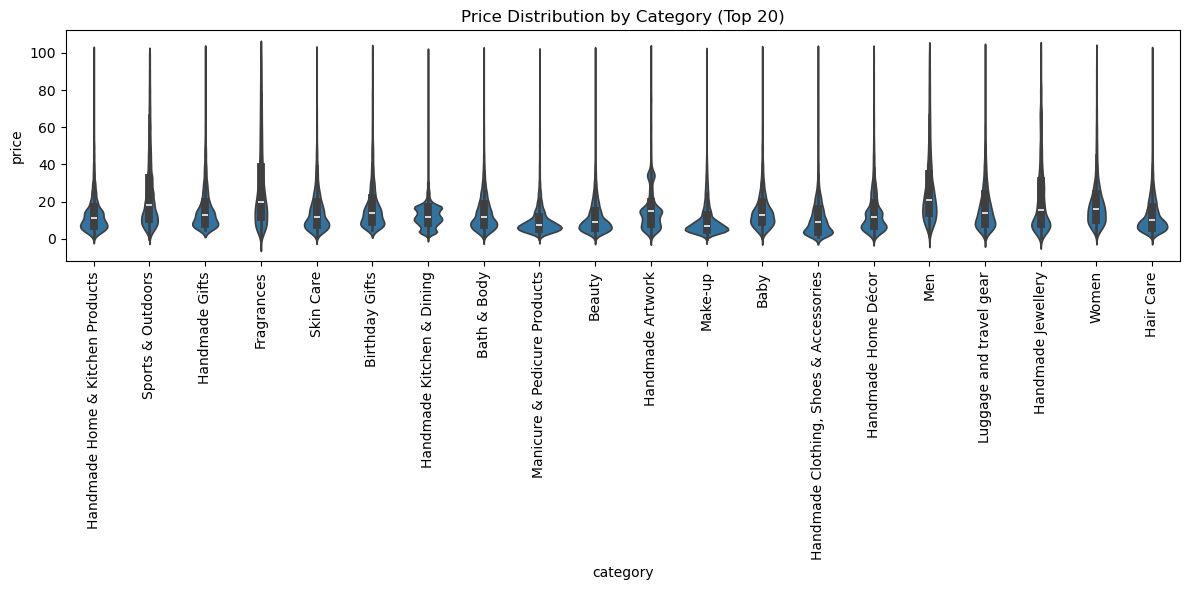

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

top20 = df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20)]

plt.figure(figsize=(12,6))
sns.violinplot(data=df_top20, x='category', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Category (Top 20)')
plt.tight_layout()
plt.show()

In [16]:
median_price = (
    df_no_outliers
    .groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

print(median_price.head(10))

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


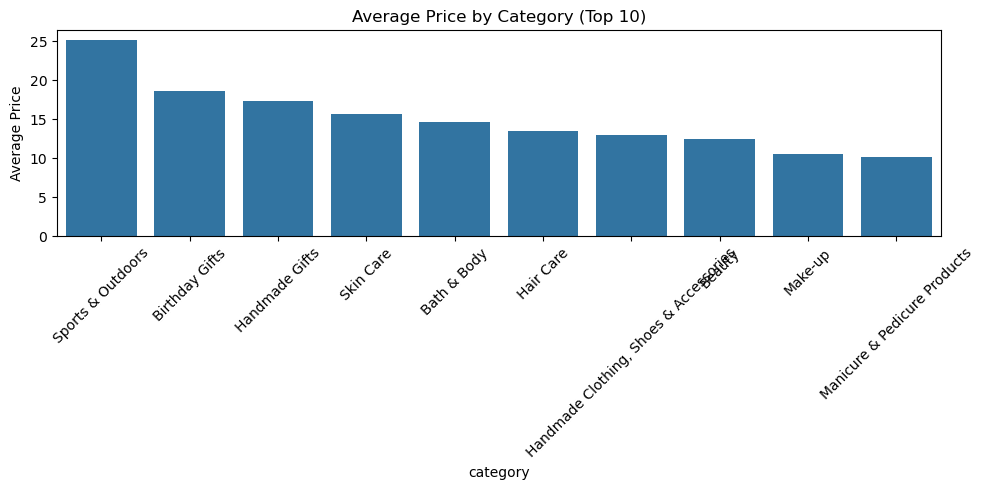

In [17]:
top10 = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10)]

avg_price = (
    df_top10
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))
sns.barplot(x=avg_price.index, y=avg_price.values)
plt.xticks(rotation=45)
plt.title('Average Price by Category (Top 10)')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

In [18]:
avg_price_all = (
    df_no_outliers
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

print(avg_price_all.head(10))

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64


In [20]:
print(df_no_outliers.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


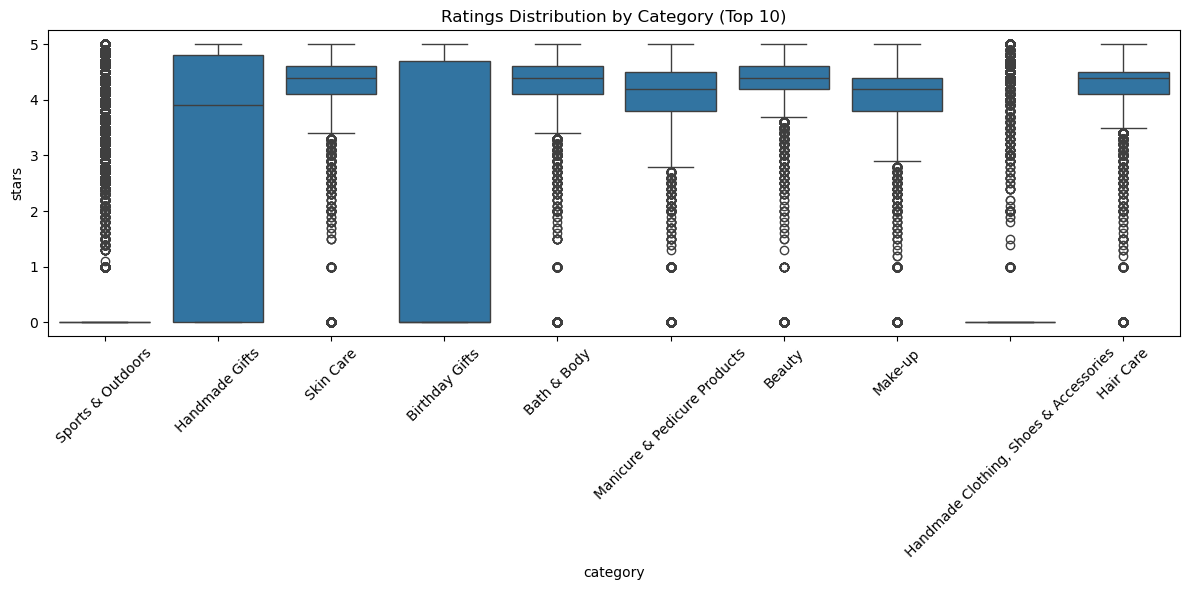

In [21]:
df_no_outliers['stars'] = pd.to_numeric(df_no_outliers['stars'], errors='coerce')
df_r = df_no_outliers.dropna(subset=['stars']).copy()

top10 = df_r['category'].value_counts().head(10).index
df_top10_r = df_r[df_r['category'].isin(top10)]

plt.figure(figsize=(12,6))
sns.boxplot(data=df_top10_r, x='category', y='stars')
plt.xticks(rotation=45)
plt.title('Ratings Distribution by Category (Top 10)')
plt.tight_layout()
plt.show()

In [22]:
median_rating = (
    df_r
    .groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

print(median_rating.head(10))

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64


In [23]:
import pandas as pd
import numpy as np

df_no_outliers['price'] = pd.to_numeric(df_no_outliers['price'], errors='coerce')
df_no_outliers['stars'] = pd.to_numeric(df_no_outliers['stars'], errors='coerce')

df_corr = df_no_outliers.dropna(subset=['price', 'stars']).copy()

In [24]:
corr = df_corr['price'].corr(df_corr['stars'])  # Pearson
print("Correlation (price vs stars):", corr)

Correlation (price vs stars): -0.07767299878178476


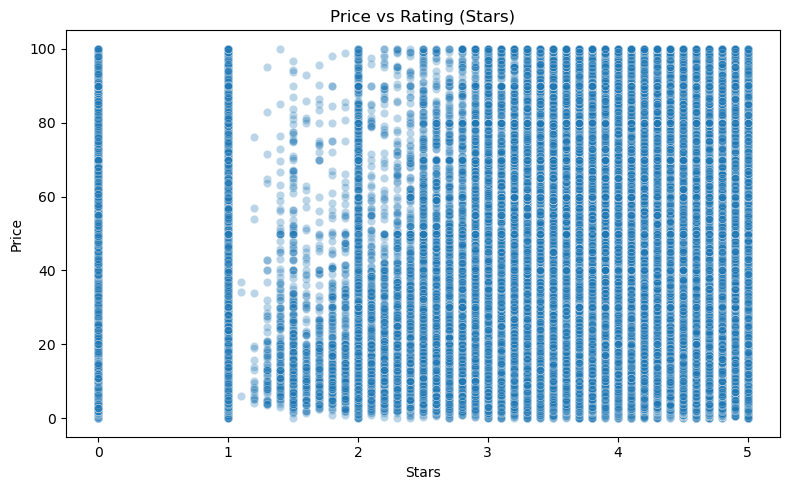

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.scatterplot(data=df_corr, x='stars', y='price', alpha=0.3)

plt.title('Price vs Rating (Stars)')
plt.xlabel('Stars')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

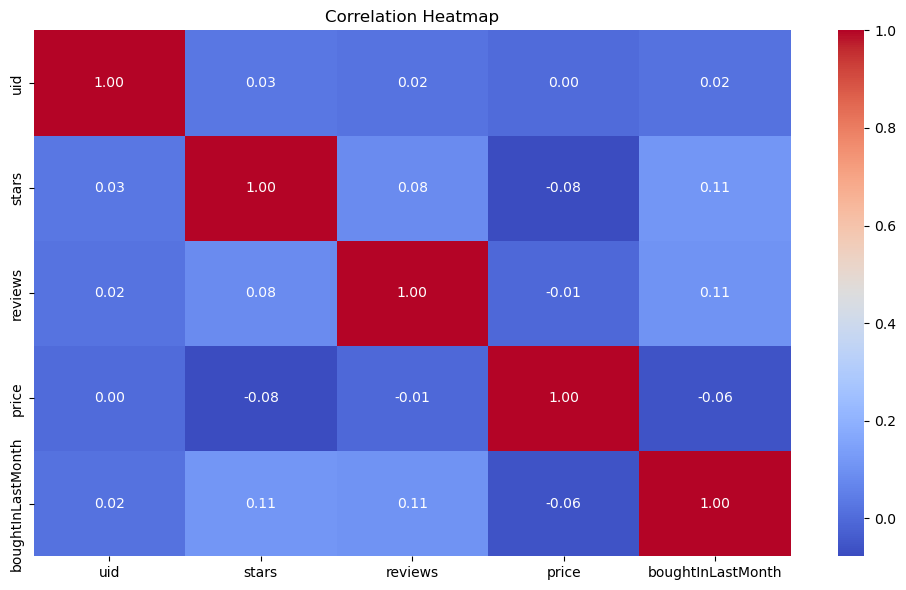

In [26]:
# selecionar apenas colunas numéricas
num_df = df_no_outliers.select_dtypes(include=['number'])

corr_matrix = num_df.corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

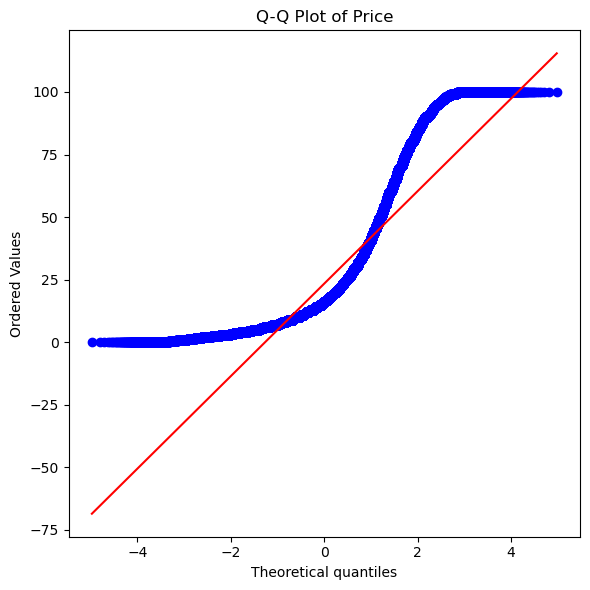

In [27]:
import scipy.stats as stats

plt.figure(figsize=(6,6))
stats.probplot(df_corr['price'], dist="norm", plot=plt)

plt.title('Q-Q Plot of Price')
plt.tight_layout()
plt.show()